# Case Study 4: Fed Tightening and the Transmission to Autos, Credit and Manufacturing

**Role:** staff to a Federal Reserve Board member preparing for the next FOMC meeting.

**Where things stand:** on Sep 16, 2026 the FOMC voted 12-0 to *raise* the target range by 1/4 pt to 3-3/4 to 4%
(after holding at 3-1/2 to 3-3/4 since January). Inflation re-accelerated because of tariffs plus an oil shock
from the Middle East conflict (late Feb 2026). The question for the next meeting: **hike again, hold, or reverse?**


| Section | Question | What it produces |
|---|---|---|
| 0 | Setup and data check | Loads `data/core_monthly.csv`, shows what's available and how current it is |
| 1 | How tight is policy right now? | Fed funds vs. the Taylor rule, the real policy rate, a snapshot table |
| 2 | Did tightening reach autos? | The transmission chain, pass-through, lags, and the chip-shortage control |
| 3 | Did it spread to credit and manufacturing? | The same analysis for business credit, delinquencies and manufacturing |
| 4 | Where are things heading? What should the Fed do? | ARIMA/ARIMAX forecasts, the Taylor-rule path, comparison with the FOMC, a recommendation |

**How to use it:** run top to bottom. After each section, fill in the **Findings** cell with one sentence per chart.
Those sentences become your report. If a chart doesn't give you a sentence, delete it.

Charts are saved to `figures/` for the slides. Requires `pandas numpy matplotlib statsmodels`.

## 0. Setup and data check

In [24]:
import warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

warnings.filterwarnings("ignore")              # statsmodels convergence chatter
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

DATA, FIG = Path("data"), Path("figures")
FIG.mkdir(exist_ok=True)

# Key policy dates (vertical markers on every chart)
EVENTS = {"2022-03-01": "First hike", "2023-07-01": "Last hike", "2024-09-01": "First cut",
          "2026-09-01": "Re-hike"}
START_PLOT = "2018-01-01"                      # assignment window: pre-trend 2018-19

# Colorblind-safe palette, fixed order (slot 1 = blue, 2 = orange, 3 = aqua, 4 = yellow)
C = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300"]
INK, MUTED = "#2b2b2b", "#8a8a85"

plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": MUTED, "axes.labelcolor": INK, "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.grid": True, "grid.color": "#e6e6e3", "grid.linewidth": 0.6,
    "lines.linewidth": 2, "legend.frameon": False, "font.size": 10, "axes.titleweight": "bold",
    "axes.titlesize": 11, "axes.titlelocation": "left",
})

def mark_events(ax, labels=True):
    """Dashed lines at first hike / last hike / first cut."""
    for d, lab in EVENTS.items():
        ax.axvline(pd.Timestamp(d), color=MUTED, ls="--", lw=1, zorder=0)
        if labels:
            ax.annotate(lab, (pd.Timestamp(d), 1), xycoords=("data", "axes fraction"),
                        xytext=(3, -10), textcoords="offset points", fontsize=8, color=MUTED)
    ax.xaxis.set_major_locator(mdates.YearLocator())
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))

def save(fig, name):
    fig.savefig(FIG / f"{name}.png", bbox_inches="tight", dpi=200)

In [25]:
df = pd.read_csv(DATA / "core_monthly.csv", index_col="date", parse_dates=True).asfreq("MS")
fomc = pd.read_csv(DATA / "fomc_projections.csv", index_col="year")
dictionary = pd.read_csv(DATA / "data_dictionary.csv")

# Real (inflation-adjusted, Dec-2019 dollars) credit quantities, deflated by headline PCE
deflator = df.pce_index / df.pce_index.loc["2019-12-01"]
df["auto_loans_real"] = df.auto_loans_bn / deflator
df["business_loans_real"] = df.business_loans_bn / deflator

# What do we have, and how current is it?
coverage = pd.DataFrame({
    "question": dictionary.set_index("column").question.reindex(df.columns),
    "first": df.apply(lambda s: s.first_valid_index()).dt.strftime("%Y-%m"),
    "last":  df.apply(lambda s: s.last_valid_index()).dt.strftime("%Y-%m"),
    "latest_value": df.apply(lambda s: s.dropna().iloc[-1] if s.notna().any() else np.nan),
    "missing_%": (100 * df.isna().mean()).round(1),
})
coverage

,question,first,last,latest_value,missing_%
fed_funds_rate,Q1,2015-01,2026-09,3.75,0.70
pce_index,Q1,2015-01,2026-08,131.58,1.40
core_pce_index,Q1,2015-01,2026-08,130.46,1.40
unemployment_rate,Q1,2015-01,2026-09,4.20,1.40
natural_unemployment,Q1,2015-01,2026-10,4.39,0.00
treasury_5y,Q2,2015-01,2026-09,4.80,0.70
auto_loan_rate,Q2,2015-02,2026-08,7.47,2.10
auto_lending_tighter,Q2,2015-01,2026-07,-4.50,2.10
auto_loans_bn,Q2,2015-01,2026-09,526.72,0.70
vehicle_sales_mn,Q2,2015-01,2026-09,16.38,0.70


**Reading the coverage table.** `last` tells you how current each series is. Quarterly series
(lending standards, delinquency, natural unemployment) lag by a quarter or more. Missing values early
on are expected: year-over-year measures need 12 prior months. When you quote a "latest" number in
the report, give its month.

In [26]:
fomc

,fomc_median_rate,fomc_median_core_pce,fomc_median_unemployment
year,,,
2026,4.10,3.40,4.10
2027,4.10,2.50,4.10
2028,3.90,2.20,4.10
2029,3.60,2.00,4.10


## 1. How tight is policy right now?

Two lenses:
1. **Real fed funds rate** = policy rate minus core inflation. Above zero means restrictive (roughly).
2. **Taylor (1993) rule**: prescribed rate = 2 + π + 0.5(π − 2) + 0.5 × output gap, where the output gap is about 1 × (u* − u) (Okun's law).
   If the actual rate is below the rule, policy is looser than the rule suggests.

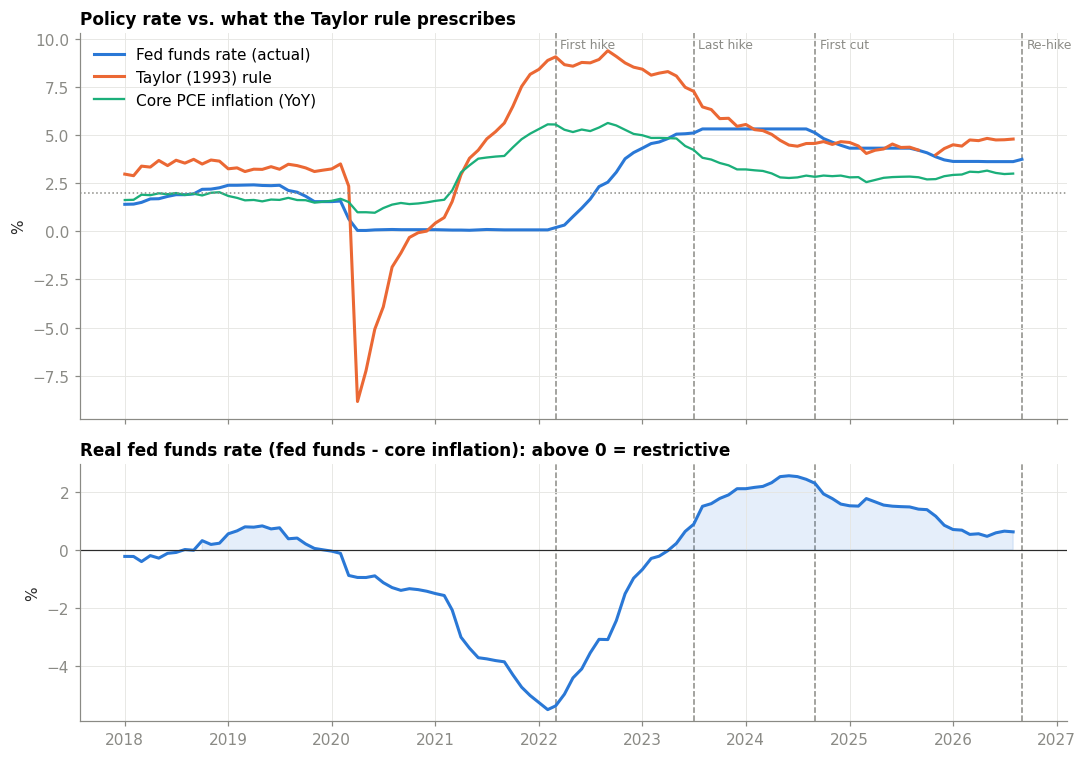

In [44]:
d = df.loc[START_PLOT:]
fig, axes = plt.subplots(2, 1, figsize=(10, 7), sharex=True, gridspec_kw={"height_ratios": [3, 2]})

ax = axes[0]
ax.plot(d.index, d.fed_funds_rate, color=C[0], label="Fed funds rate (actual)")
ax.plot(d.index, d.taylor_rule_rate, color=C[1], label="Taylor (1993) rule")
ax.plot(d.index, d.core_inflation, color=C[2], lw=1.5, label="Core PCE inflation (YoY)")
ax.axhline(2, color=MUTED, lw=1, ls=":")
ax.set_ylabel("%"); ax.set_title("Policy rate vs. what the Taylor rule prescribes")
ax.legend(loc="upper left"); mark_events(ax)

ax = axes[1]
ax.plot(d.index, d.real_fed_funds, color=C[0])
ax.axhline(0, color=INK, lw=0.8)
ax.fill_between(d.index, d.real_fed_funds, 0, where=d.real_fed_funds > 0, color=C[0], alpha=0.12)
ax.set_ylabel("%"); ax.set_title("Real fed funds rate (fed funds - core inflation): above 0 = restrictive")
mark_events(ax, labels=False)
fig.tight_layout(); save(fig, "q1_policy_stance"); plt.show()

In [45]:
# Snapshot: latest value of each stance indicator (with the month it refers to)
snap_cols = ["fed_funds_rate", "headline_inflation", "core_inflation", "unemployment_rate",
             "natural_unemployment", "unemployment_gap", "real_fed_funds", "taylor_rule_rate",
             "policy_vs_taylor"]
snapshot = pd.DataFrame({
    "latest": [df[c].dropna().iloc[-1] for c in snap_cols],
    "as_of": [df[c].last_valid_index().strftime("%Y-%m") for c in snap_cols],
    "12m_ago": [df[c].dropna().iloc[-13] for c in snap_cols],
}, index=snap_cols)
snapshot["change_12m"] = snapshot.latest - snapshot["12m_ago"]
snapshot

,latest,as_of,12m_ago,change_12m
fed_funds_rate,3.75,2026-09,4.22,-0.47
headline_inflation,3.42,2026-08,2.69,0.72
core_inflation,3.01,2026-08,2.85,0.16
unemployment_rate,4.20,2026-09,4.30,-0.10
natural_unemployment,4.39,2026-10,4.40,-0.01
unemployment_gap,0.19,2026-09,0.10,0.09
real_fed_funds,0.62,2026-08,1.48,-0.86
taylor_rule_rate,4.80,2026-08,4.37,0.44
policy_vs_taylor,-1.17,2026-08,-0.04,-1.14


**Robustness check: the Taylor rule depends on assumptions.** The neutral real rate r* is uncertain.
The current monetary policy report recommends around 0.75-1; recent estimates are closer to 0.5 to 1.5%. The weight on slack also varies (0.5 in the original, 1.0 in the "balanced" variant).

In [46]:
pi = df.core_inflation.dropna().iloc[-1]
gap = 2 * df.unemployment_gap.dropna().iloc[-1]          # output-gap equivalent
ffr = df.fed_funds_rate.dropna().iloc[-1]
grid = pd.DataFrame({f"slack wt {w}": [rstar + pi + 0.5 * (pi - 2) + w * gap for rstar in (0.5, 1.0, 1.5, 2.0)]
                     for w in (0.5, 1.0)}, index=[f"r* = {r}" for r in (0.5, 1.0, 1.5, 2.0)])
print(f"Current fed funds: {ffr:.2f}%   |   cells show rule-prescribed rate (%); "
      f"positive gap to current => rule says tighter")
(grid - 3.875).round(2)   # rule minus current target midpoint: + means rule says tighter

Current fed funds: 3.75%   |   cells show rule-prescribed rate (%); positive gap to current => rule says tighter


,slack wt 0.5,slack wt 1.0
r* = 0.5,0.33,0.52
r* = 1.0,0.83,1.02
r* = 1.5,1.33,1.52
r* = 2.0,1.83,2.02


## 2. Did tightening reach autos?

Read the panels in order. Each is one link in the chain:
**market rates → auto-loan pricing → bank lending standards → auto-credit quantity → vehicle sales → production.**
The last panel is the **control**: used-car prices spiked in 2021, before any hike, because of the chip shortage.
Don't credit the Fed with production weakness that came from the supply side.

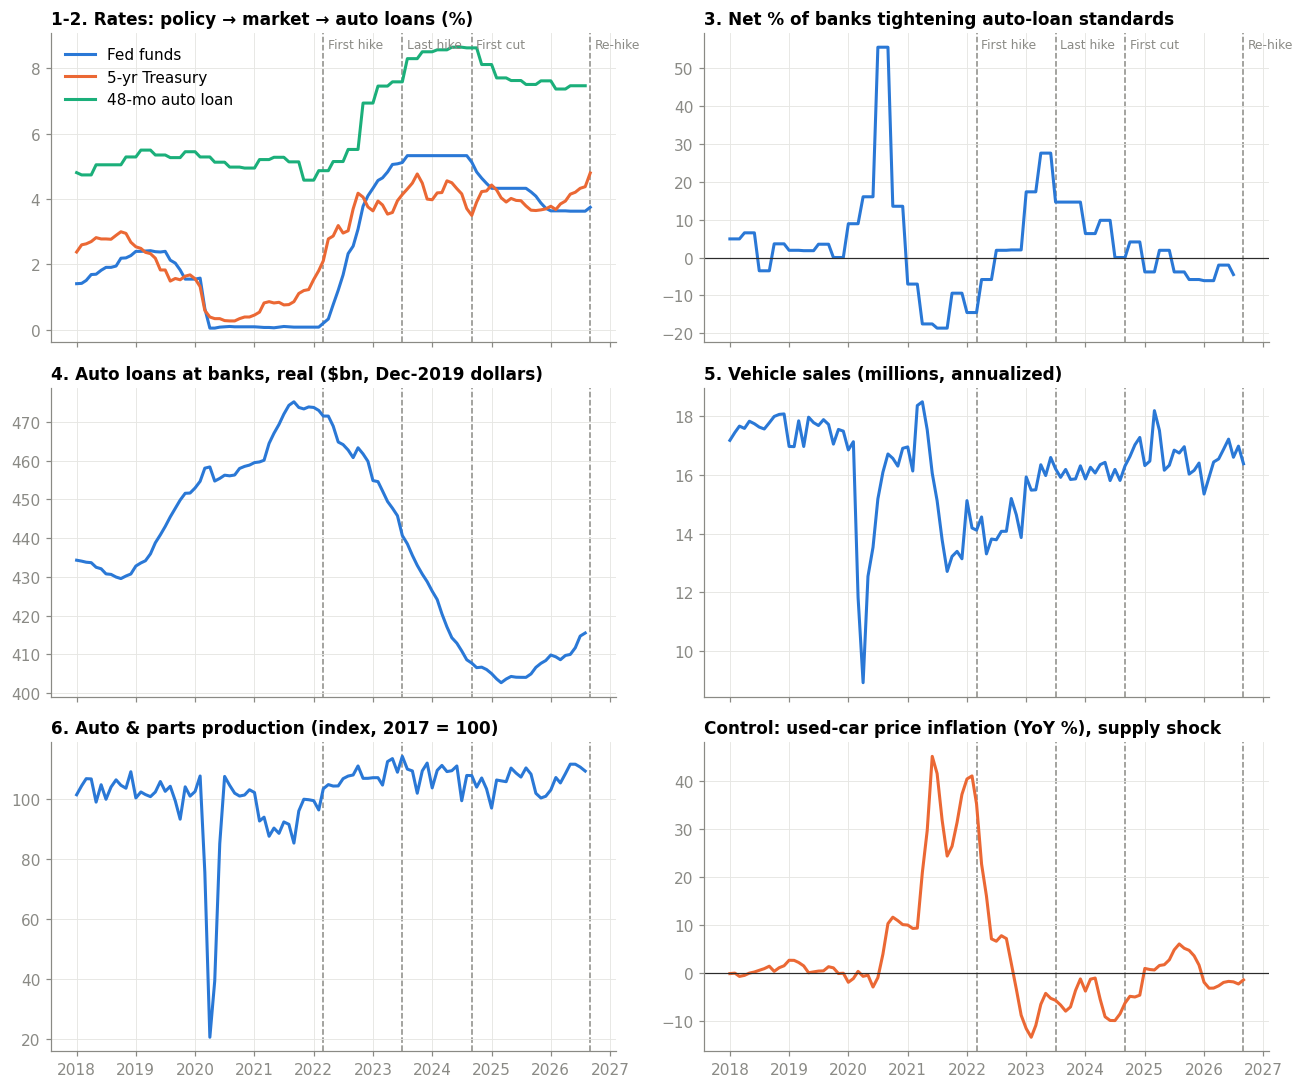

In [30]:
d = df.loc[START_PLOT:]
fig, axes = plt.subplots(3, 2, figsize=(12, 10), sharex=True)
ax = axes.ravel()

ax[0].plot(d.index, d.fed_funds_rate, color=C[0], label="Fed funds")
ax[0].plot(d.index, d.treasury_5y, color=C[1], label="5-yr Treasury")
ax[0].plot(d.index, d.auto_loan_rate, color=C[2], label="48-mo auto loan")
ax[0].set_title("1-2. Rates: policy → market → auto loans (%)"); ax[0].legend(loc="upper left")

ax[1].plot(d.index, d.auto_lending_tighter, color=C[0])
ax[1].axhline(0, color=INK, lw=0.8)
ax[1].set_title("3. Net % of banks tightening auto-loan standards")

ax[2].plot(d.index, d.auto_loans_real, color=C[0])
ax[2].set_title("4. Auto loans at banks, real ($bn, Dec-2019 dollars)")

ax[3].plot(d.index, d.vehicle_sales_mn, color=C[0])
ax[3].set_title("5. Vehicle sales (millions, annualized)")

ax[4].plot(d.index, d.auto_production_idx, color=C[0])
ax[4].set_title("6. Auto & parts production (index, 2017 = 100)")

ax[5].plot(d.index, d.used_car_inflation, color=C[1])
ax[5].axhline(0, color=INK, lw=0.8)
ax[5].set_title("Control: used-car price inflation (YoY %), supply shock")

for i, a in enumerate(ax):
    mark_events(a, labels=(i < 2))
fig.tight_layout(); save(fig, "q2_auto_chain"); plt.show()

### 2a. Pass-through: how much of the rate increase reached auto borrowers?
Two measures:
- **Cycle change**: from Feb 2022 (just before the first hike) to each series' peak during the tightening cycle.
- **Regression beta**: 12-month change in the auto-loan rate on the 12-month change in the 5-yr Treasury.
  A beta of 1 means one-for-one pass-through.

In [31]:
pre = "2022-02-01"
cycle = df.loc["2022-03-01":"2024-12-01"]
rates = ["fed_funds_rate", "treasury_5y", "auto_loan_rate"]
pt = pd.DataFrame({
    "pre_hike (Feb-22)": df.loc[pre, rates],
    "cycle_peak": cycle[rates].max(),
    "peak_month": cycle[rates].idxmax().dt.strftime("%Y-%m"),
})
pt["increase_pp"] = pt.cycle_peak - pt["pre_hike (Feb-22)"]
pt["share_of_fed_funds_increase"] = pt.increase_pp / pt.loc["fed_funds_rate", "increase_pp"]
display(pt)

# OLS pass-through beta (numpy, no extra deps). Overlapping 12m changes => SEs are understated; report beta only.
x = df.treasury_5y.diff(12); y = df.auto_loan_rate.diff(12)
m = pd.concat([x, y], axis=1).loc[START_PLOT:].dropna()
X = np.column_stack([np.ones(len(m)), m.iloc[:, 0]])
beta = np.linalg.lstsq(X, m.iloc[:, 1], rcond=None)[0]
r2 = 1 - ((m.iloc[:, 1] - X @ beta) ** 2).sum() / ((m.iloc[:, 1] - m.iloc[:, 1].mean()) ** 2).sum()
print(f"Pass-through beta (Δ12 auto rate on Δ12 5y Treasury, {m.index[0]:%Y-%m}+): {beta[1]:.2f}   R² = {r2:.2f}")
auto_spread_now = df.auto_loan_spread.dropna()
print(f"Auto-loan spread over 5y: pre-hike {df.loc[pre,'auto_loan_spread']:.2f} pp → latest "
      f"{auto_spread_now.iloc[-1]:.2f} pp ({auto_spread_now.index[-1]:%Y-%m})")

,pre_hike (Feb-22),cycle_peak,peak_month,increase_pp,share_of_fed_funds_increase
fed_funds_rate,0.08,5.33,2023-08,5.25,1.00
treasury_5y,1.81,4.77,2023-10,2.96,0.56
auto_loan_rate,4.87,8.65,2024-05,3.78,0.72


Pass-through beta (Δ12 auto rate on Δ12 5y Treasury, 2018-01+): 0.38   R² = 0.19
Auto-loan spread over 5y: pre-hike 3.06 pp → latest 3.09 pp (2026-08)


### 2b. Lags: how long does each link take to respond?

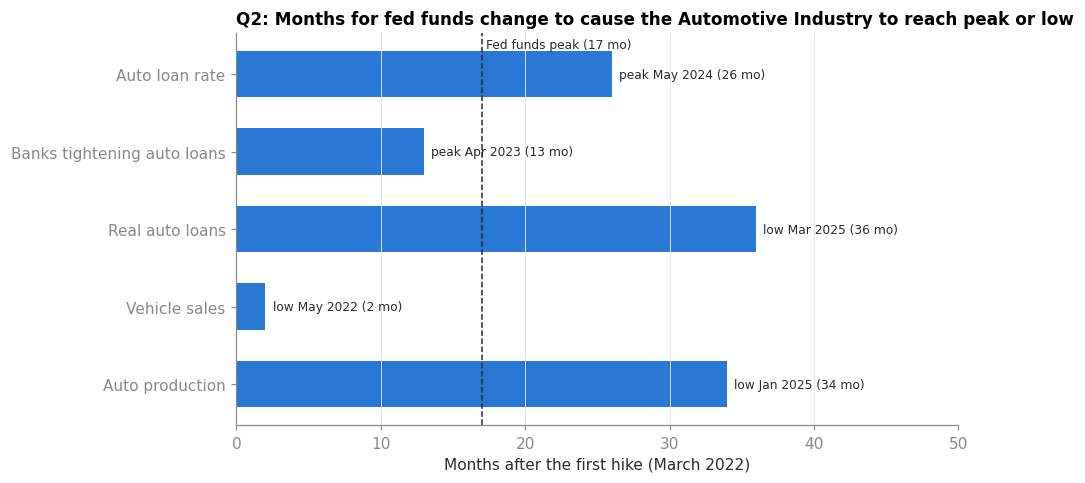

,turning point,date,months after first hike
variable,,,
Auto loan rate,peak,May 2024,26
Banks tightening auto loans,peak,Apr 2023,13
Real auto loans,low,Mar 2025,36
Vehicle sales,low,May 2022,2
Auto production,low,Jan 2025,34


In [49]:
def lag_profile(driver, response, max_lag=24, start=START_PLOT):
    """corr(driver_t, response_{t+k}) for k = 0..max_lag."""
    out = {}
    for k in range(max_lag + 1):
        pair = pd.concat([driver, response.shift(-k)], axis=1).loc[start:].dropna()
        out[k] = pair.iloc[:, 0].corr(pair.iloc[:, 1]) if len(pair) > 24 else np.nan
    return pd.Series(out)

def yoy(s):
    return 100 * (s / s.shift(12) - 1)

driver = df.fed_funds_rate.diff(12)
responses_q2 = {
    "Auto loan rate":                 df.auto_loan_rate,
    "Banks tightening auto loans":    df.auto_lending_tighter,
    "Real auto loans":                df.auto_loans_real,
    "Vehicle sales":                  df.vehicle_sales_mn,
    "Auto production":                df.auto_production_idx,
}

def lag_table_and_chart(responses, title, fname,
                        first_hike="2022-03-01", window_end="2025-12-01"):
    """For each variable: how many months after the first hike did it reach its peak (or low)?
    Rates, bank tightening and delinquency -> peak. Loans, sales, production, output -> low."""
    start = pd.Timestamp(first_hike)
    rows = []
    for label, s in responses.items():
        s = s.loc[first_hike:window_end].dropna()
        kind = "peak" if any(w in label.lower() for w in ("rate", "tightening", "delinquen")) else "low"
        when = s.idxmax() if kind == "peak" else s.idxmin()
        months = (when.year - start.year) * 12 + (when.month - start.month)
        rows.append({"variable": label, "turning point": kind, "date": when.strftime("%b %Y"),
                    "months after first hike": months})
    summary = pd.DataFrame(rows).set_index("variable")

    # Fed funds peak, as a reference line
    ff = df.fed_funds_rate.loc[first_hike:window_end]
    ff_months = (ff.idxmax().year - start.year) * 12 + (ff.idxmax().month - start.month)

    fig, ax = plt.subplots(figsize=(9, 0.6 * len(summary) + 1.5))
    y = list(range(len(summary)))[::-1]
    ax.barh(y, summary["months after first hike"], color=C[0], height=0.6)
    for yi, (m, d, k) in zip(y, summary[["months after first hike", "date", "turning point"]].values):
        ax.text(m + 0.5, yi, f"{k} {d} ({m} mo)", va="center", fontsize=8, color=INK)
    ax.axvline(ff_months, color=INK, ls="--", lw=1)
    ax.annotate(f"Fed funds peak ({ff_months} mo)", (ff_months, 1), xycoords=("data", "axes fraction"),
                xytext=(3, -10), textcoords="offset points", fontsize=8, color=INK)
    ax.set_yticks(y); ax.set_yticklabels(summary.index)
    ax.set_xlabel("Months after the first hike (March 2022)")
    ax.set_xlim(0, summary["months after first hike"].max() + 14)
    ax.grid(axis="y", visible=False)
    ax.set_title(title)
    fig.tight_layout(); save(fig, fname); plt.show()
    return summary

lag_table_and_chart(responses_q2, "Q2: Months for fed funds change to cause the Automotive Industry to reach peak or low",
                    "q2_lags")

### 2c. Separating the chip shortage from the Fed
If auto production was already falling **before** March 2022 while used-car prices were surging,
that weakness is supply-driven. Compare the pre-hike and post-hike windows.

In [33]:
windows = {"Supply shock (Jan-21 to Feb-22)": ("2021-01-01", "2022-02-01"),
           "Hiking (Mar-22 to Jul-23)":       ("2022-03-01", "2023-07-01"),
           "Hold + easing (Aug-23 to Dec-25)": ("2023-08-01", "2025-12-01"),
           "2026 oil shock (Jan-26 to latest)": ("2026-01-01", None)}
rows = {}
for name, (a, b) in windows.items():
    w = df.loc[a:b]
    rows[name] = {
        "used_car_inflation_avg": w.used_car_inflation.mean(),
        "auto_production_change_%": 100 * (w.auto_production_idx.dropna().iloc[-1] / w.auto_production_idx.dropna().iloc[0] - 1),
        "vehicle_sales_avg_mn": w.vehicle_sales_mn.mean(),
        "auto_loan_rate_avg": w.auto_loan_rate.mean(),
    }
pd.DataFrame(rows).T

,used_car_inflation_avg,auto_production_change_%,vehicle_sales_avg_mn,auto_loan_rate_avg
Supply shock (Jan-21 to Feb-22),28.53,-5.69,15.30,5.03
Hiking (Mar-22 to Jul-23),2.04,10.46,14.91,6.34
Hold + easing (Aug-23 to Dec-25),-2.17,-8.22,16.42,8.14
2026 oil shock (Jan-26 to latest),-2.27,6.10,16.48,7.45


## 3. Did it spread to wider credit and manufacturing?
The same logic as Q2, applied to business lending, household credit stress and manufacturing output.

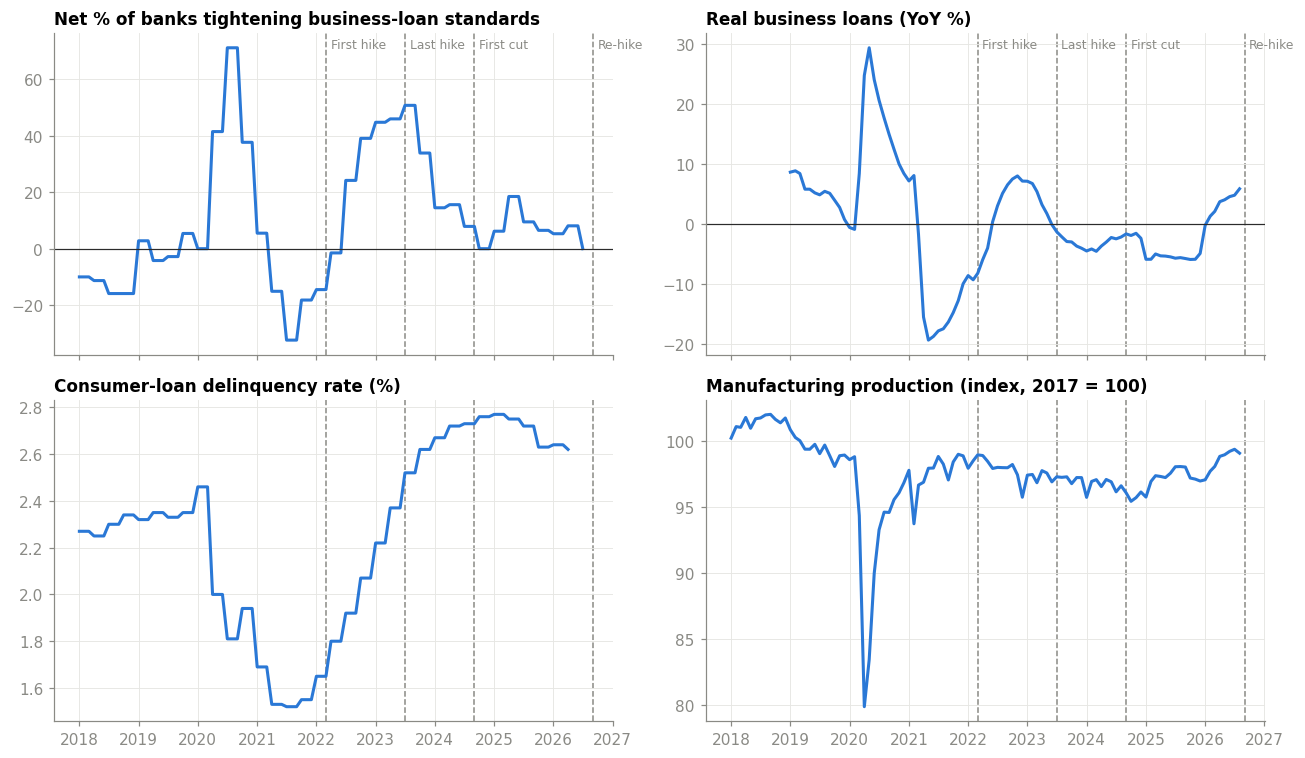

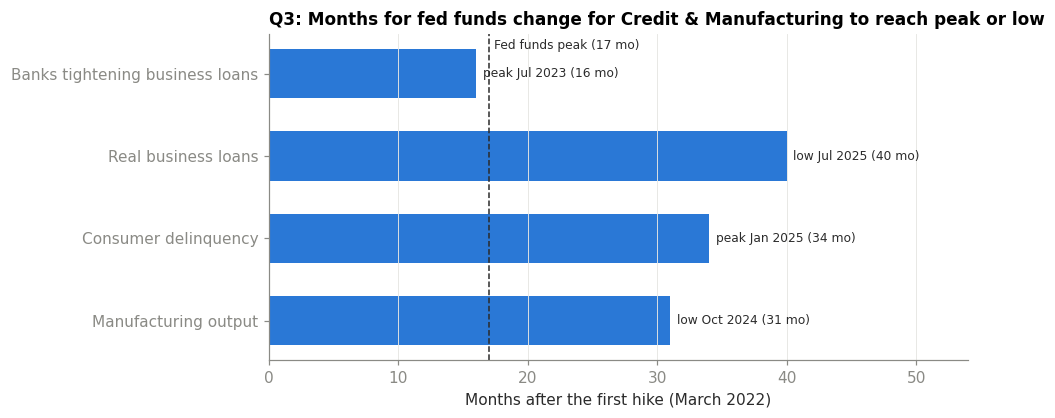

,turning point,date,months after first hike
variable,,,
Banks tightening business loans,peak,Jul 2023,16
Real business loans,low,Jul 2025,40
Consumer delinquency,peak,Jan 2025,34
Manufacturing output,low,Oct 2024,31


In [50]:
d = df.loc[START_PLOT:]
fig, axes = plt.subplots(2, 2, figsize=(12, 7), sharex=True)
ax = axes.ravel()
ax[0].plot(d.index, d.business_lending_tighter, color=C[0]); ax[0].axhline(0, color=INK, lw=0.8)
ax[0].set_title("Net % of banks tightening business-loan standards")
ax[1].plot(d.index, yoy(d.business_loans_real), color=C[0]); ax[1].axhline(0, color=INK, lw=0.8)
ax[1].set_title("Real business loans (YoY %)")
ax[2].plot(d.index, d.consumer_delinquency, color=C[0])
ax[2].set_title("Consumer-loan delinquency rate (%)")
ax[3].plot(d.index, d.manufacturing_idx, color=C[0])
ax[3].set_title("Manufacturing production (index, 2017 = 100)")
for i, a in enumerate(ax):
    mark_events(a, labels=(i < 2))
fig.tight_layout(); save(fig, "q3_credit_mfg"); plt.show()

responses_q3 = {
    "Banks tightening business loans": df.business_lending_tighter,
    "Real business loans":             df.business_loans_real,
    "Consumer delinquency":            df.consumer_delinquency,
    "Manufacturing output":            df.manufacturing_idx,
}
lag_table_and_chart(responses_q3, "Q3: Months for fed funds change for Credit & Manufacturing to reach peak or low",
                    "q3_lags")

## 4. Where are things heading, and what should the Fed do?

**Plan:**
1. Forecast the two Taylor-rule inputs, **core inflation** and **unemployment**, 12 months ahead with ARIMA.
2. Check whether **oil** improves the inflation forecast (ARIMAX). This is how geopolitics (wars → oil) enters the model.
3. **Validate honestly:** hold out the last 12 months and compare against a naive forecast. A model that can't beat naive shouldn't drive a recommendation.
4. Feed the forecasts into the Taylor rule → a prescribed rate path → compare with today's rate and the FOMC's own projections.

**Modeling choices:**
- Inflation is modeled as the **monthly annualized change in log core PCE**. YoY inflation is rebuilt from it, which avoids modeling overlapping YoY numbers.
- Unemployment is modeled in **levels with d = 1**, trained from **Jul-2021**. The 2020 COVID spike (to ~15%) would dominate any ARIMA fit.

In [35]:
from statsmodels.tsa.statespace.sarimax import SARIMAX

H = 12                                                        # forecast horizon (months)
infl_m = (1200 * np.log(df.core_pce_index).diff()).dropna()   # monthly, annualized, log %
unemp = df.unemployment_rate.loc["2021-07-01":].dropna()
oil = df.oil_price.dropna()
oil_x = (100 * np.log(oil).diff(3)).shift(1)                  # 3m % change in oil, known one month ahead

def yoy_from_monthly(m):
    """YoY log inflation = average of the last 12 annualized monthly rates."""
    return m.rolling(12).mean()

def fit_best(y, d, trend, exog=None, max_p=2, max_q=2):
    """Small AIC grid over (p, d, q)."""
    best = None
    for p in range(max_p + 1):
        for q in range(max_q + 1):
            try:
                r = SARIMAX(y, exog=exog, order=(p, d, q), trend=trend).fit(disp=False)
                if best is None or r.aic < best[1].aic:
                    best = ((p, d, q), r)
            except Exception:
                pass
    return best

def rmse(a, b):
    return float(np.sqrt(np.mean((np.asarray(a) - np.asarray(b)) ** 2)))

### 4a. Holdout test (last 12 months)

In [36]:
cut = infl_m.index[-H]                                        # first holdout month
tr_i, te_i = infl_m.loc[:cut - pd.offsets.MonthBegin()], infl_m.loc[cut:]

# --- inflation: ARIMA, ARIMAX(oil), naive (monthly pace = trailing-12m average, i.e. YoY stays flat)
order_i, res_i = fit_best(tr_i, 0, "c")
fc_arima = pd.Series(res_i.get_forecast(len(te_i)).predicted_mean.values, te_i.index)

X = oil_x.reindex(infl_m.index)
ok = X.notna()
tr_x = X.loc[tr_i.index][ok.loc[tr_i.index]]
order_x, res_x = fit_best(tr_i.loc[tr_x.index], 0, "c", exog=tr_x)
fc_arimax = pd.Series(res_x.get_forecast(len(te_i), exog=X.loc[te_i.index].values.reshape(-1, 1))
                      .predicted_mean.values, te_i.index)
fc_naive = pd.Series(tr_i.iloc[-12:].mean(), te_i.index)

def to_yoy(fc):  # splice forecast onto history, rebuild YoY on the holdout months
    return yoy_from_monthly(pd.concat([tr_i, fc])).loc[te_i.index]
actual_yoy = yoy_from_monthly(infl_m).loc[te_i.index]

# --- unemployment: ARIMA vs. naive (last value)
tr_u, te_u = unemp.loc[:cut - pd.offsets.MonthBegin()], unemp.loc[cut:]
order_u, res_u = fit_best(tr_u, 1, "n")
fc_u = pd.Series(res_u.get_forecast(len(te_u)).predicted_mean.values, te_u.index)

holdout = pd.DataFrame({
    "model order": [str(order_i), str(order_x) + " + oil", "naive", str(order_u), "naive"],
    "RMSE": [rmse(to_yoy(fc_arima), actual_yoy), rmse(to_yoy(fc_arimax), actual_yoy),
             rmse(to_yoy(fc_naive), actual_yoy), rmse(fc_u, te_u), rmse([tr_u.iloc[-1]] * len(te_u), te_u)],
}, index=["Core inflation: ARIMA", "Core inflation: ARIMAX (oil)*", "Core inflation: naive",
          "Unemployment: ARIMA", "Unemployment: naive"])
holdout["RMSE"] = holdout.RMSE.round(3)
print(f"Holdout: {te_i.index[0]:%Y-%m} to {te_i.index[-1]:%Y-%m}  (inflation RMSE on YoY %, unemployment on level %)")
print("* ARIMAX uses realized oil in the holdout (oracle exog), so it's an upper bound on oil's usefulness.")
holdout

Holdout: 2025-09 to 2026-08  (inflation RMSE on YoY %, unemployment on level %)
* ARIMAX uses realized oil in the holdout (oracle exog), so it's an upper bound on oil's usefulness.


,model order,RMSE
Core inflation: ARIMA,"(2, 0, 1)",0.28
Core inflation: ARIMAX (oil)*,"(2, 0, 1) + oil",0.24
Core inflation: naive,naive,0.19
Unemployment: ARIMA,"(1, 1, 2)",0.26
Unemployment: naive,naive,0.12


**How to read this:** ARIMAX beats ARIMA, oil carries real information, which supports the geopolitical-risk argument.

### 4b. 12-month forecasts with oil scenarios

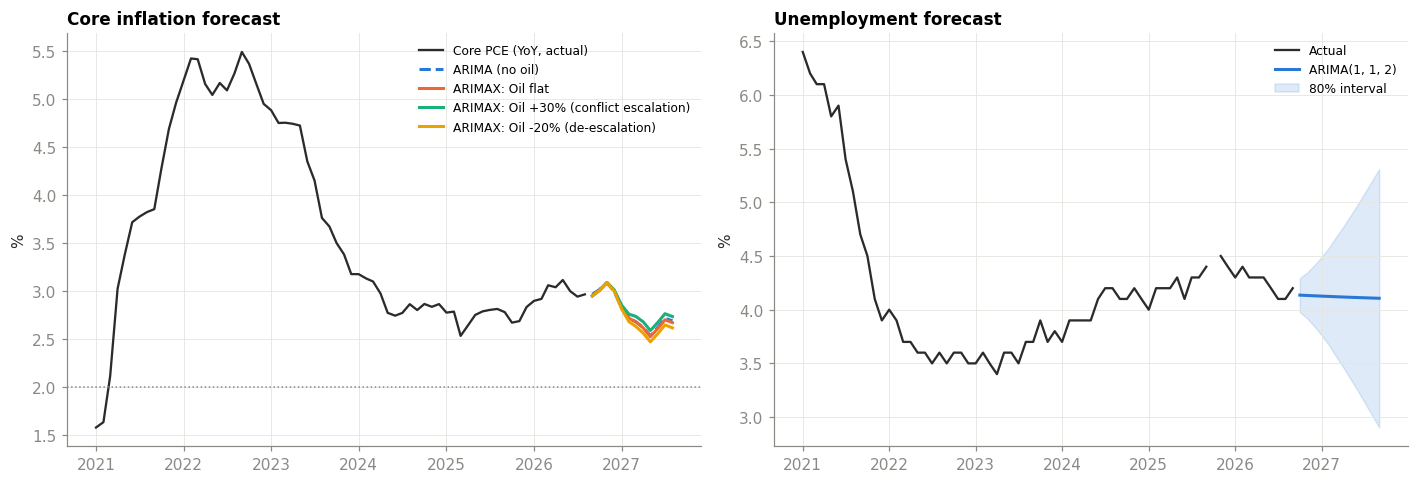

Chosen orders - inflation ARIMA(2, 0, 1), ARIMAX(2, 0, 1), unemployment ARIMA(1, 1, 2)


In [37]:
# Refit on the full sample
order_i, res_i = fit_best(infl_m, 0, "c")
order_u, res_u = fit_best(unemp, 1, "n")
Xfull = oil_x.reindex(infl_m.index).dropna()
order_x, res_x = fit_best(infl_m.loc[Xfull.index], 0, "c", exog=Xfull)

f_idx = pd.date_range(infl_m.index[-1] + pd.offsets.MonthBegin(), periods=H, freq="MS")
u_idx = pd.date_range(unemp.index[-1] + pd.offsets.MonthBegin(), periods=H, freq="MS")

def oil_scenario(total_pct, months=3):
    """Oil path: move total_pct over `months`, then flat. Returns exog for the forecast window."""
    last = oil.iloc[-1]
    path_idx = pd.date_range(oil.index[-1] + pd.offsets.MonthBegin(), f_idx[-1], freq="MS")
    steps = np.minimum(np.arange(1, len(path_idx) + 1), months) / months
    path = pd.Series(last * (1 + total_pct / 100) ** steps, path_idx)
    full = pd.concat([oil, path])
    return (100 * np.log(full).diff(3)).shift(1).reindex(f_idx).values.reshape(-1, 1)

scenarios = {"Oil flat": 0, "Oil +30% (conflict escalation)": 30, "Oil -20% (de-escalation)": -20}
infl_paths = {"ARIMA (no oil)": yoy_from_monthly(pd.concat(
    [infl_m, pd.Series(res_i.get_forecast(H).predicted_mean.values, f_idx)])).loc[f_idx]}
for name, pct in scenarios.items():
    fc = pd.Series(res_x.get_forecast(H, exog=oil_scenario(pct)).predicted_mean.values, f_idx)
    infl_paths[f"ARIMAX: {name}"] = yoy_from_monthly(pd.concat([infl_m, fc])).loc[f_idx]
infl_paths = pd.DataFrame(infl_paths)

unemp = unemp.asfreq("MS")  # Keep missing months as NaN; SARIMAX supports them.
order_u, res_u = fit_best(unemp, 1, "n")
fu = res_u.get_forecast(steps=H)
unemp_fc = pd.DataFrame({"forecast": fu.predicted_mean.values,
                         "lo80": fu.conf_int(alpha=0.2).iloc[:, 0].values,
                         "hi80": fu.conf_int(alpha=0.2).iloc[:, 1].values}, index=u_idx)

hist = df.loc["2021-01-01":]
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
ax = axes[0]
ax.plot(hist.index, yoy_from_monthly(infl_m).reindex(hist.index), color=INK, lw=1.5, label="Core PCE (YoY, actual)")
for i, c in enumerate(infl_paths):
    ax.plot(infl_paths.index, infl_paths[c], color=C[i], ls="-" if i else "--", label=c)
ax.axhline(2, color=MUTED, ls=":", lw=1); ax.set_ylabel("%"); ax.set_title("Core inflation forecast")
ax.legend(fontsize=8, loc="upper right")
ax = axes[1]
ax.plot(hist.index, hist.unemployment_rate, color=INK, lw=1.5, label="Actual")
ax.plot(unemp_fc.index, unemp_fc.forecast, color=C[0], label=f"ARIMA{order_u}")
ax.fill_between(unemp_fc.index, unemp_fc.lo80, unemp_fc.hi80, color=C[0], alpha=0.15, label="80% interval")
ax.set_ylabel("%"); ax.set_title("Unemployment forecast"); ax.legend(fontsize=8)
for a in axes:
    a.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
fig.tight_layout(); save(fig, "q4_forecasts"); plt.show()
print(f"Chosen orders - inflation ARIMA{order_i}, ARIMAX{order_x}, unemployment ARIMA{order_u}")

### 4c. From forecasts to a policy rate

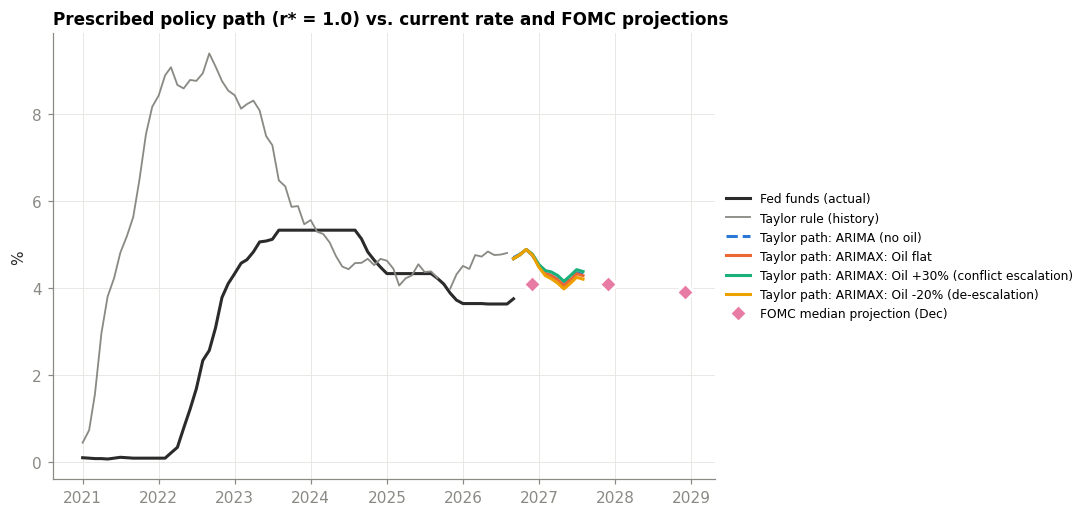

,in 3 months,in 12 months,current_ffr,gap_3m_pp
ARIMA (no oil),4.88,4.31,3.75,1.13
ARIMAX: Oil flat,4.89,4.28,3.75,1.14
ARIMAX: Oil +30% (conflict escalation),4.89,4.38,3.75,1.14
ARIMAX: Oil -20% (de-escalation),4.89,4.20,3.75,1.14


In [41]:
u_star = df.natural_unemployment.dropna().iloc[-1]
RSTAR = 1.0                                                  # change to test sensitivity (see Q1 grid)

def taylor(pi, u, rstar=RSTAR):
    return rstar + pi + 0.5 * (pi - 2) + 0.5 * 2 * (u_star - u)

u_path = unemp_fc.forecast.reindex(infl_paths.index).ffill().bfill()
rate_paths = infl_paths.apply(lambda col: taylor(col, u_path))

ffr_now = df.fed_funds_rate.dropna()
fig, ax = plt.subplots(figsize=(10, 4.8))
h = df.loc["2021-01-01":]
ax.plot(h.index, h.fed_funds_rate, color=INK, label="Fed funds (actual)")
ax.plot(h.index, h.taylor_rule_rate, color=MUTED, lw=1.2, label="Taylor rule (history)")
for i, c in enumerate(rate_paths):
    ax.plot(rate_paths.index, rate_paths[c], color=C[i], ls="-" if i else "--", label=f"Taylor path: {c}")
# FOMC median projection plotted at December of each year
fy = fomc.fomc_median_rate.dropna()
fy = fy[fy.index <= rate_paths.index[-1].year + 1]
ax.plot(pd.to_datetime([f"{y}-12-01" for y in fy.index]), fy.values, "D", ms=8, color=C[4],
        mec="white", mew=2, label="FOMC median projection (Dec)")
ax.set_ylabel("%"); ax.set_title(f"Prescribed policy path (r* = {RSTAR}) vs. current rate and FOMC projections")
ax.legend(fontsize=8, loc="center left", bbox_to_anchor=(1, 0.5))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
fig.tight_layout(); save(fig, "q4_policy_path"); plt.show()

summary = pd.DataFrame({
    "in 3 months": rate_paths.iloc[2], "in 12 months": rate_paths.iloc[-1],
}).assign(current_ffr=ffr_now.iloc[-1])
summary["gap_3m_pp"] = summary["in 3 months"] - summary.current_ffr
summary

In [42]:
# Compare our year-end forecasts to the FOMC's medians (Q4 values ≈ December)
rows = []
for yr in fomc.index:
    dec = pd.Timestamp(f"{yr}-12-01")
    if dec in infl_paths.index:
        rows.append({"year": yr,
                     "our core PCE (flat oil)": infl_paths.loc[dec, "ARIMAX: Oil flat"],
                     "FOMC core PCE": fomc.loc[yr, "fomc_median_core_pce"],
                     "our unemployment": u_path.loc[dec],
                     "FOMC unemployment": fomc.loc[yr, "fomc_median_unemployment"],
                     "our Taylor rate": rate_paths.loc[dec, "ARIMAX: Oil flat"],
                     "FOMC rate": fomc.loc[yr, "fomc_median_rate"]})
pd.DataFrame(rows).set_index("year") if rows else print("Forecast window doesn't reach a December in the FOMC table.")

,our core PCE (flat oil),FOMC core PCE,our unemployment,FOMC unemployment,our Taylor rate,FOMC rate
year,,,,,,
2026,3.00,3.40,4.13,4.10,4.77,4.10


### 4d. Recommendation (starting point, not the answer)
A mechanical rule: compare the Taylor-prescribed rate **3 months out** (baseline, flat oil) with the current rate.
- gap > +0.25 pp → **tighten** · gap < −0.25 pp → **ease** · otherwise → **hold**

In [43]:
base = rate_paths["ARIMAX: Oil flat"]
gap3 = base.iloc[2] - ffr_now.iloc[-1]
mech = "TIGHTEN" if gap3 > 0.25 else "EASE" if gap3 < -0.25 else "HOLD"
print(f"Current fed funds {ffr_now.iloc[-1]:.2f}% ({ffr_now.index[-1]:%Y-%m}); "
      f"Taylor (r*={RSTAR}) in 3m: {base.iloc[2]:.2f}%  → gap {gap3:+.2f} pp → mechanical call: {mech}")
for c in rate_paths:
    g = rate_paths[c].iloc[2] - ffr_now.iloc[-1]
    print(f"  {c:40s} gap {g:+.2f} pp → {'TIGHTEN' if g > .25 else 'EASE' if g < -.25 else 'HOLD'}")

Current fed funds 3.75% (2026-09); Taylor (r*=1.0) in 3m: 4.89%  → gap +1.14 pp → mechanical call: TIGHTEN
  ARIMA (no oil)                           gap +1.13 pp → TIGHTEN
  ARIMAX: Oil flat                         gap +1.14 pp → TIGHTEN
  ARIMAX: Oil +30% (conflict escalation)   gap +1.14 pp → TIGHTEN
  ARIMAX: Oil -20% (de-escalation)         gap +1.14 pp → TIGHTEN
